# Ghost Lakes — results and tests
Every number in `WRITEUP.md`, recomputed from the files in `outputs/`. **No Earth Engine account needed**: this notebook only reads saved results (`python run.py --help` lists the steps that made them).

1. Terrain AI: how well does it generalise?  2. Terrain AI on documented drained lakes  3. Abidjan: the sites  4. Abidjan: how good are the estimates?  5. Global screen: precision  6. Where it fails

In [1]:
import json, pandas as pd
from IPython.display import display
pd.set_option('display.width', 160)
load = lambda p: json.load(open(p, encoding='utf-8'))

## 1. Terrain AI: leave-one-region-out
Random Forest on 10 terrain features, trained on 6 Romanian regions, tested on the 7th. Test sets are balanced 50/50 water/dry, so these numbers are optimistic.

,n,auc,f1,precision,recall
bucuresti,4000.0,0.974,0.919,0.939,0.900
timisoara,4000.0,0.982,0.933,0.966,0.901
iasi,3000.0,0.986,0.929,0.961,0.899
cluj,3000.0,0.987,0.834,0.988,0.722
galati,3000.0,0.975,0.909,0.959,0.864
craiova,3000.0,0.986,0.936,0.940,0.933
oradea,3000.0,0.948,0.884,0.972,0.811


mean AUC 0.977  mean F1 0.906


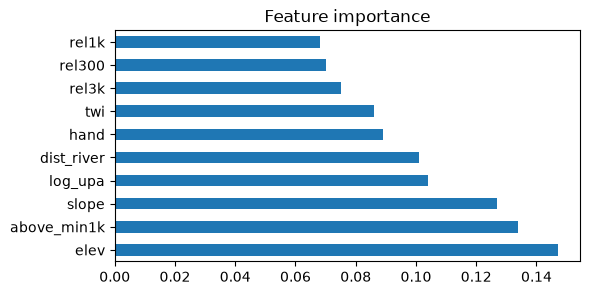

In [2]:
m = load('outputs/metrics.json')
display(pd.DataFrame(m['leave_one_region_out']).T[['n', 'auc', 'f1', 'precision', 'recall']])
print('mean AUC', m['mean_auc'], ' mean F1', m['mean_f1'])
pd.Series(m['feature_importance']).plot.barh(title='Feature importance', figsize=(6, 3));

## 2. Terrain AI on documented drained water bodies (Bucharest)
Trained **without** any Bucharest data; sites compared with random land pixels of the city.

In [3]:
v = load('outputs/validation_bucuresti.json')
display(pd.DataFrame(v['sites'])[['site', 'group', 'p_water', 'percentile']])
print({k: v[k] for k in v if k.startswith('auc_') or k.startswith('n_')})

,site,group,p_water,percentile
0,Balta Icoanei (Lacul Bulindroi),vanished,0.126872,56.133333
1,Balta de la Carvasara (Lacul Șuțu),vanished,0.047705,21.800000
2,Pârâul Dâmbovicioara (Calea Rahovei),vanished,0.178532,69.933333
3,Pârâul Bucureștioara (Colțea -> Unirii),vanished,0.246576,80.133333
4,Balta lui Dura (Cișmigiu marsh),lake_remains,0.399029,92.266667
5,Balta Cocioc (Tineretului),lake_remains,0.499998,95.866667


{'auc_vanished': 0.57, 'n_vanished': 4, 'auc_lake_remains': 0.941, 'n_lake_remains': 2, 'auc_all': 0.694, 'n_all': 6}


**Honest reading:** on water bodies that vanished completely the terrain model is close to chance (AUC ≈ 0.57, n = 4). That is why the findings come from the satellite archive and radar, not terrain alone.

## 3. Abidjan: the sites
Lagoon water for decades (JRC ≥ 50 %), water in H1 2023, sand or buildings in 2026, and radar-confirmed.

In [4]:
s = pd.read_csv('outputs/abidjan/abidjan_sites.csv')
display(s[['site', 'neighbourhood', 'area_ha', 'optical_land_from', 'radar_land_from', 'dates_agree', 'people_within_500m']])
print(f"{len(s)} sites, {s.area_ha.sum():.1f} ha; from 2024 on: {s[s.optical_land_from >= '2024-01'].area_ha.sum():.1f} ha")
p = load('outputs/abidjan_population.json')['people_within_m']
print('people within 500 m of any site:', p['500'], ' within 1 km:', p['1000'])

,site,neighbourhood,area_ha,optical_land_from,radar_land_from,dates_agree,people_within_500m
0,1,Vridi,7.79,2024-08,2025-02-05,False,6394
1,2,Les Grands Moulins,7.55,2025-11,2025-10-15,True,8831
2,3,"Zone 3, Abidjan",5.12,2026-02,2025-11-14,True,4098
3,4,Les Grands Moulins,3.17,2025-09,2024-04-23,False,9009
4,5,"Koumassi, Abidjan",2.55,2024-04,2024-03-30,True,19410
5,6,"Vridi, Abidjan",1.82,2024-09,2024-09-14,True,2214
6,7,"M’pouto, Abidjan",1.36,2025-12,2024-11-13,False,1581
7,8,"Koumassi, Abidjan",1.23,2026-07,2026-04-19,True,16952
8,9,"Koumassi, Abidjan",1.03,2023-10,2023-11-07,True,17677
9,10,Petit Bassam,0.77,2026-07,2026-04-13,True,5269


11 sites, 33.0 ha; from 2024 on: 32.0 ha
people within 500 m of any site: 75373  within 1 km: 313610


![Abidjan before/after and timeline](outputs/abidjan/figure_before_after.png)

![Abidjan timelapse 2023-2026](outputs/abidjan/timelapse.gif)

**Visual proof, every site up close** (700 m window; 2023 H1, 2024 H2, 2025 H2, 2026): inside each red outline, dark water becomes sand.

![Every site at four dates](outputs/abidjan/sites_zoom.png)

## 4. Abidjan: how good are the estimates?

In [5]:
a = load('outputs/abidjan_accuracy.json')
inside = a['inside_polygon_ha']
print('Area inside the polygons (ha):', inside)
print(f"  confirmed by reflectance rule: {inside['refl'] / inside['dw']:.0%}, by radar: {inside['radar'] / inside['dw']:.0%}, by both: {inside['both'] / inside['dw']:.0%}")
print('With a 20 m margin (extent):', a['totals_ha'])

Area inside the polygons (ha): {'dw': 33.04, 'refl': 32.53, 'radar': 30.05, 'both': 29.8}
  confirmed by reflectance rule: 98%, by radar: 91%, by both: 90%
With a 20 m margin (extent): {'dw': 33.04, 'refl': 46.54, 'radar': 44.02}


In [6]:
g = pd.DataFrame(a['threshold_grid'])
display(g.pivot_table(index=['then_water', 'now_water'], columns='land', values='area_ha'))
ok = g[g.then_water < 0.8]
print(f'thresholds 0.6-0.7: {ok.area_ha.min():.1f} - {ok.area_ha.max():.1f} ha; 0.8 gives 0 because '
      'Dynamic World rarely reaches P(water) >= 0.8 in this turbid lagoon')

land                    0.4    0.5    0.6
then_water now_water                     
0.6        0.1        33.34  33.10  26.43
           0.2        41.58  39.88  27.14
           0.3        46.69  40.88  27.14
0.7        0.1        25.42  25.36  19.81
           0.2        32.19  30.86  20.61
           0.3        35.80  30.99  20.61
0.8        0.1         0.00   0.00   0.00
           0.2         0.00   0.00   0.00
           0.3         0.00   0.00   0.00

thresholds 0.6-0.7: 19.8 - 46.7 ha; 0.8 gives 0 because Dynamic World rarely reaches P(water) >= 0.8 in this turbid lagoon


In [7]:
print('Fill dates: optical and radar agree within 3 months for', int(s.dates_agree.sum()), 'of', len(s), 'sites')
display(s[['site', 'optical_last_water', 'optical_land_from', 'radar_last_water', 'radar_land_from', 'dates_agree']])

Fill dates: optical and radar agree within 3 months for 7 of 11 sites


,site,optical_last_water,optical_land_from,radar_last_water,radar_land_from,dates_agree
0,1,2024-03,2024-08,2024-06-10,2025-02-05,False
1,2,2025-09,2025-11,2025-10-09,2025-10-15,True
2,3,2024-11,2026-02,2025-07-17,2025-11-14,True
3,4,2024-11,2025-09,2024-04-11,2024-04-23,False
4,5,2023-05,2024-04,2023-12-13,2024-03-30,True
5,6,2024-05,2024-09,2024-08-09,2024-09-14,True
6,7,2024-03,2025-12,2024-11-01,2024-11-13,False
7,8,2026-03,2026-07,2026-04-07,2026-04-19,True
8,9,2023-05,2023-10,2023-10-14,2023-11-07,True
9,10,2026-02,2026-07,2026-03-14,2026-04-13,True


Sites 8 and 10: radar still sees open water on 14 March / 7 April 2026 and land from mid-April, so they were filled **after** the minister's 11 February 2026 warning. Both sensors agree.

## 5. Global screen: precision of the 2023→2026 infill detector
~120 cities. Every radar-confirmed patch was checked by eye (Sentinel-2 2023 vs 2026) and labelled.

In [8]:
lab = pd.read_csv('outputs/recent_infill/labels.csv')
c = lab.groupby('label').agg(patches=('city', 'size'), area_ha=('area_ha', 'sum'))
c['share_patches'] = (c.patches / c.patches.sum()).round(2)
c['share_area'] = (c.area_ha / c.area_ha.sum()).round(2)
display(c)
display(lab.groupby(['city', 'label', 'note']).area_ha.agg(['size', 'sum']).round(1))

,patches,area_ha,share_patches,share_area
label,,,,
drained,1,1.22,0.03,0.00
infill,23,326.26,0.79,0.95
natural,5,15.13,0.17,0.04


,,,size,sum
city,label,note,,
abidjan,infill,"Ébrié lagoon fill (sand platforms), checked optical+radar",8,29.0
colombo,infill,port / Port City reclamation,2,22.8
dakar,infill,port extension into the sea,1,14.9
lima,natural,beach / coastline change,2,2.3
manila,infill,Manila Bay reclamation / port extension,10,255.5
phnom_penh,infill,riverside channel filled,1,2.7
rajshahi,natural,Padma river channel moved,1,9.1
ro_bucuresti,drained,"Herastrau lake drained for works, June 2026 (temporary, documented)",1,1.2
vijayawada,natural,Krishna river sand bar,2,3.8


## 6. Where it fails
| Failure | Evidence | Consequence |
|---|---|---|
| Terrain AI cannot see lakes that left no terrain trace | AUC 0.57 on 4 documented Bucharest sites | Only a hint; findings come from archive + radar |
| Terrain AI top candidates in Romania were artefacts | sunken stadium pitch, excavations, quarries | No Romanian discovery claimed |
| Moving rivers and beaches look like infill | 5 of 29 global radar-confirmed patches | Human review required; next: mask river channels and shorelines |
| Dates uncertain for some sites | optical vs radar differ 6–20 months for 4 of 11 Abidjan sites | Reported as ranges |
| MNDWI water index fails in this turbid, hazy lagoon | open water MNDWI ≈ -0.1…-0.2 | Replaced by a NIR/SWIR rule |
| Cannot tell legal from illegal fill | port areas in Vridi | We never claim illegality |
| Small fills (< 0.5 ha) not counted | design choice | 33 ha is a lower bound |